# Module 2 – Cible et découpage train / validation / test

À partir de `games_clean` et `reviews_clean` (module 1) :
1. calculer, pour chaque jeu, le nombre d'avis et la part d'avis positifs pendant sa **première année** ;
2. découper les jeux **par date de sortie** : 70 % en train, 15 % en validation, 15 % en test ;
3. définir le **succès** avec un seuil calculé **sur le train seulement** ;
4. regarder la distribution de la cible par split et dans le temps.

Fichier produit : `target.parquet` (`app_id`, `release_date`, `n_reviews_1y`, `pos_ratio_1y`, `success`, `split`), utilisé par les modules 3 et 4.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config import *

games = pd.read_parquet(PROC_DIR / "games_clean.parquet", columns=["app_id", "release_date"])
reviews = pd.read_parquet(PROC_DIR / "reviews_clean.parquet", columns=["app_id", "date", "days", "is_recommended"])
print("Jeux :", len(games), "| Avis :", len(reviews))

Jeux : 10000 | Avis : 6833248


## 1. Garder les jeux qui ont une année complète d'avis

Pour mesurer le succès à un an, il faut avoir observé toute la première année. Un jeu sorti moins d'un an avant le dernier avis du jeu de données aurait une année incomplète, donc moins d'avis. Il serait compté à tort comme un échec.

In [2]:
last_review = reviews["date"].max()
full_year = games["release_date"] + pd.Timedelta(days=HORIZON_DAYS) <= last_review

print("Dernier avis du jeu de données :", last_review.date())
print("Jeux sans année complète d'avis (retirés) :", (~full_year).sum())
games = games[full_year]

Dernier avis du jeu de données : 2022-12-31
Jeux sans année complète d'avis (retirés) : 0


Nos jeux sont sortis entre 2015 et 2021, et les avis vont jusqu'au 31/12/2022 : tous ont une année complète, aucun n'est retiré. La vérification reste utile si le sous-ensemble de jeux change (par exemple avec des jeux de 2022).

## 2. Nombre d'avis et part d'avis positifs la première année

On ne garde que les avis postés pendant la première année : `0 <= days < 365`. Les avis avec `days < 0` (accès anticipé) ont déjà été retirés au module 1.

On part de **tous les jeux** avec une jointure `left` : un jeu sans aucun avis garde `n_reviews_1y = 0`. Si on partait des avis, ces jeux disparaîtraient : on ne garderait que des jeux qui ont reçu au moins un avis, et on surestimerait le taux de succès (**biais du survivant**). Leur `pos_ratio_1y` reste vide : sans avis, la part d'avis positifs n'existe pas.

In [3]:
year1 = reviews[reviews["days"] < HORIZON_DAYS]
assert year1["days"].between(0, HORIZON_DAYS - 1).all()  # aucun avis hors de la première année

counts = year1.groupby("app_id").agg(
    n_reviews_1y=("is_recommended", "size"),  # nombre d'avis
    pos_ratio_1y=("is_recommended", "mean"),  # moyenne de True/False = part d'avis positifs
)
target = games.merge(counts, on="app_id", how="left")  # left : les jeux sans avis sont gardés
target["n_reviews_1y"] = target["n_reviews_1y"].fillna(0).astype(int)

print("Jeux sans aucun avis la première année :", (target["n_reviews_1y"] == 0).sum())
target["n_reviews_1y"].describe()

Jeux sans aucun avis la première année : 2200


count    10000.0000
mean       271.8203
std       2191.8992
min          0.0000
25%          2.0000
50%         12.0000
75%         46.0000
max      71110.0000
Name: n_reviews_1y, dtype: float64

## 3. Découpage par date de sortie

On ne mélange **pas** les jeux au hasard (`train_test_split`). Le modèle doit prédire le succès de jeux **futurs** à partir de jeux **passés** : on entraîne sur les jeux les plus anciens et on évalue sur les plus récents. Un découpage aléatoire mettrait des jeux de 2021 dans le train et des jeux de 2016 dans le test. Le modèle verrait alors « l'avenir » (tendances, nouvelles catégories) et son score serait trop optimiste.

On coupe **sur les dates** elles-mêmes : la date qui sépare les 70 % de jeux les plus anciens (fin du train), puis celle des 85 % (fin de la validation). Tous les jeux sortis le même jour tombent donc dans le **même** split. Le découpage provisoire des modules 3 et 4 coupait sur le rang des jeux : les 8 jeux sortis le 20/05/2020 étaient répartis entre le train et la validation.

In [4]:
d_train = target["release_date"].quantile(SPLIT[0])           # 70 % des jeux sortent avant cette date
d_val = target["release_date"].quantile(SPLIT[0] + SPLIT[1])  # 85 % des jeux sortent avant cette date

target["split"] = np.where(target["release_date"] <= d_train, "train",
                  np.where(target["release_date"] <= d_val, "val", "test"))

# Aucun chevauchement : chaque split commence après la fin du précédent
dates = target.groupby("split")["release_date"]
assert dates.max()["train"] < dates.min()["val"] and dates.max()["val"] < dates.min()["test"]

print("Fin du train :", d_train.date(), "| fin de la validation :", d_val.date())
dates.agg(["count", "min", "max"]).loc[["train", "val", "test"]]

Fin du train : 2020-05-20 | fin de la validation : 2021-03-29


,count,min,max
split,,,
train,7007,2015-01-01,2020-05-20
val,1499,2020-05-21,2021-03-29
test,1494,2021-03-30,2021-12-31


## 4. Définition du succès

Un jeu est un **succès** s'il est dans le **top 20 %** en nombre d'avis la première année **et** s'il a **au moins 80 %** d'avis positifs :
- le nombre d'avis mesure la **popularité** (il est lié au nombre de joueurs) ;
- la part d'avis positifs mesure la **satisfaction**. Un jeu très joué mais détesté n'est pas un succès.

Le seuil du top 20 % est le 80e centile de `n_reviews_1y` **calculé sur le train seulement**, puis appliqué tel quel à la validation et au test. Le calculer sur tous les jeux serait une **fuite de données** : le nombre d'avis des jeux de validation et de test influencerait la définition de la cible.

Un seuil relatif (top 20 %) plutôt qu'un nombre fixe d'avis : le nombre d'avis dépend beaucoup de l'époque et de l'échantillon, alors que « faire partie des jeux les plus commentés » garde le même sens.

In [5]:
threshold = target.loc[target["split"] == "train", "n_reviews_1y"].quantile(TOP_QUANTILE)  # TRAIN seulement
target["success"] = (target["n_reviews_1y"] >= threshold) & (target["pos_ratio_1y"] >= MIN_POS_RATIO)

print("Seuil (80e centile du train) :", threshold, "avis la première année")

Seuil (80e centile du train) : 66.0 avis la première année


Un jeu sans avis a `pos_ratio_1y` vide : la comparaison `>= 0.8` donne False, donc ce n'est pas un succès.

Combien de jeux du train remplissent chaque condition ?

In [6]:
train = target[target["split"] == "train"]
pd.crosstab(train["n_reviews_1y"] >= threshold, train["pos_ratio_1y"] >= MIN_POS_RATIO,
            rownames=["top 20 % en avis"], colnames=["≥ 80 % positifs"], margins=True)

≥ 80 % positifs,False,True,All
top 20 % en avis,,,
False,3493,2107,5600
True,483,924,1407
All,3976,3031,7007


**Lecture :** dans le train, 1 407 jeux (20,1 %) sont dans le top 20 % en nombre d'avis. Parmi eux, 924 ont aussi au moins 80 % d'avis positifs : ce sont les succès. Les 483 autres sont populaires mais trop critiqués. La condition de satisfaction retire donc environ un tiers des jeux populaires.

## 5. Distribution de la cible

In [7]:
target.groupby("split")["success"].agg(n_jeux="size", n_succes="sum", taux="mean").loc[["train", "val", "test"]]

,n_jeux,n_succes,taux
split,,,
train,7007,924,0.131868
val,1499,235,0.156771
test,1494,222,0.148594


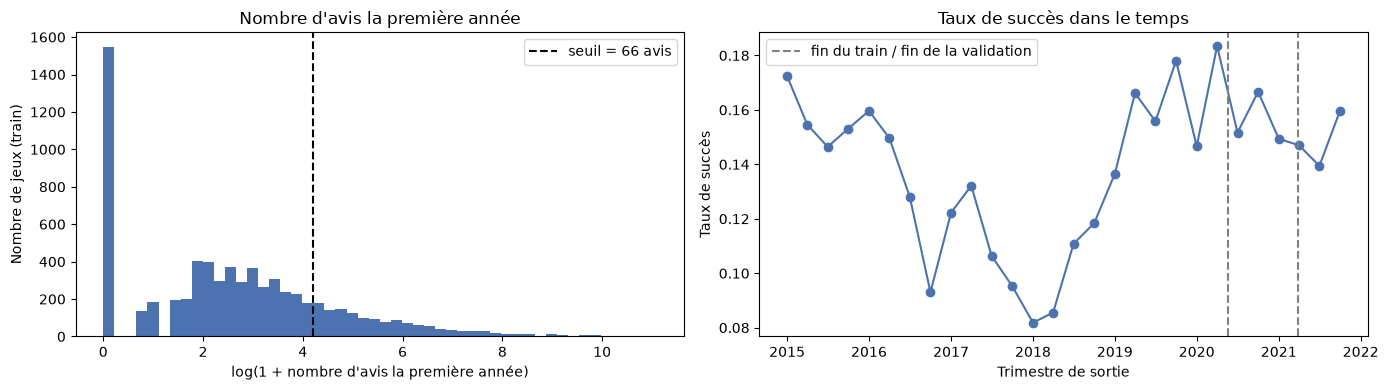

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Nombre d'avis la première année (échelle log), avec le seuil du top 20 %
axes[0].hist(np.log1p(train["n_reviews_1y"]), bins=50, color="#4C72B0")
axes[0].axvline(np.log1p(threshold), color="black", linestyle="--", label=f"seuil = {threshold:.0f} avis")
axes[0].set_xlabel("log(1 + nombre d'avis la première année)")
axes[0].set_ylabel("Nombre de jeux (train)")
axes[0].set_title("Nombre d'avis la première année")
axes[0].legend()

# Taux de succès par trimestre de sortie, avec les limites des splits
by_quarter = target.groupby(target["release_date"].dt.to_period("Q"))["success"].mean()
axes[1].plot(by_quarter.index.to_timestamp(), by_quarter.values, marker="o", color="#4C72B0")
axes[1].axvline(d_train, color="gray", linestyle="--", label="fin du train / fin de la validation")
axes[1].axvline(d_val, color="gray", linestyle="--")
axes[1].set_xlabel("Trimestre de sortie")
axes[1].set_ylabel("Taux de succès")
axes[1].set_title("Taux de succès dans le temps")
axes[1].legend()

plt.tight_layout()
plt.show()

**Lecture :**
- **Classes déséquilibrées :** environ 1 jeu sur 7 est un succès (13,2 % dans le train). L'accuracy est donc trompeuse : un modèle qui répond toujours « échec » aurait environ 86 % d'accuracy. La métrique principale est la PR-AUC, et le module 4 utilise `class_weight="balanced"`.
- **22 % des jeux n'ont aucun avis la première année** (2 200 jeux). Ils sont gardés comme des échecs, et c'est ce qui évite le biais du survivant.
- **Le nombre d'avis est très asymétrique :** médiane de 11 avis dans le train, maximum de 65 059. Le seuil de 66 avis est donc bas en valeur absolue : il suffit d'environ 66 avis la première année pour être dans le top 20 % de notre échantillon.
- **Le taux de succès change dans le temps :** autour de 15-17 % en 2015, il descend à 8-12 % en 2017-2018, puis remonte à 15-18 % à partir de 2019. La validation (15,7 %) et le test (14,9 %) ont donc plus de succès que le train (13,2 %). C'est un **changement de distribution** : une hypothèse est l'arrivée massive de petits jeux sur Steam à partir de 2017 (ouverture de Steam Direct), qui aurait fait baisser la part de succès. Conséquences :
  - la PR-AUC d'un modèle au hasard vaut la proportion de succès : elle n'est pas la même en validation et en test, donc on compare toujours un modèle à la baseline **du même split** ;
  - un modèle entraîné sur des années où les succès sont rares peut sous-estimer les probabilités sur des années plus récentes.

## 6. Enregistrement

In [9]:
target = target[["app_id", "release_date", "n_reviews_1y", "pos_ratio_1y", "success", "split"]]
assert target["app_id"].is_unique

target.to_parquet(PROC_DIR / "target.parquet", index=False)
print("Enregistré : target.parquet", target.shape)

Enregistré : target.parquet (10000, 6)


**Pour les modules 3 et 4 :** remplacer le découpage et la cible provisoires par la lecture de `target.parquet`, pour que tout le projet utilise exactement le même découpage et le même seuil.

**Créneau 3 (à venir) :** déséquilibre des classes (`class_weight` comparé à un rééchantillonnage **dans** le pipeline), intervalles de confiance à 95 % par bootstrap sur la validation, et test apparié pour comparer deux modèles.